# Visualize WadiGaza change across year pairs

Load the saved all-years result tables and create figures focused on WadiGaza across the six consecutive-year pairs. This notebook does not recompute statistics.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from change_ci.plotting import (
    plot_change_heatmap,
    plot_change_small_multiples,
    plot_change_timeseries,
    plot_correlogram,
    plot_n_eff,
    save_figure,
)

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"

## Load saved outputs

In [2]:
RESULTS_DIR = ROOT / 'outputs' / 'change_ci' / 'all_year_pairs_2019_2025'
PLOT_DIR = RESULTS_DIR / 'plots'
results = pd.read_csv(RESULTS_DIR / 'results.csv')
correlograms = pd.read_csv(RESULTS_DIR / 'correlograms.csv')
primary = results.loc[results['is_primary_tau']].copy()
wadi = primary.loc[primary['study_area'] == 'WadiGaza'].copy()
print(f'{len(primary)} primary results overall; {len(wadi)} for WadiGaza; {len(correlograms)} correlogram rows')

168 primary results overall; 24 for WadiGaza; 12744 correlogram rows


## WadiGaza mean change by month and year pair

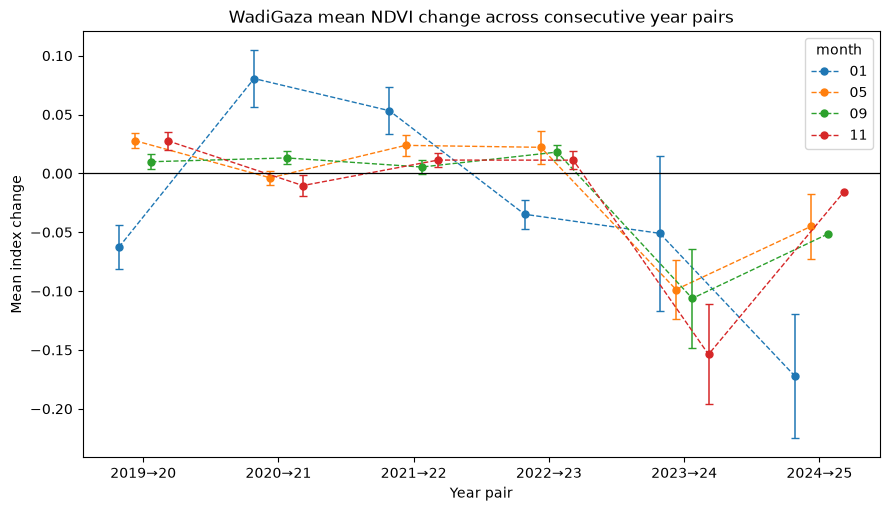

In [3]:
fig, ax = plot_change_timeseries(
    wadi, group_by='month', show_ci_for='all',
)
ax.set_title('WadiGaza mean NDVI change across consecutive year pairs')
save_figure(fig, PLOT_DIR / 'WadiGaza_mean_change_timeseries.png')
plt.show()

## Monthly small multiples

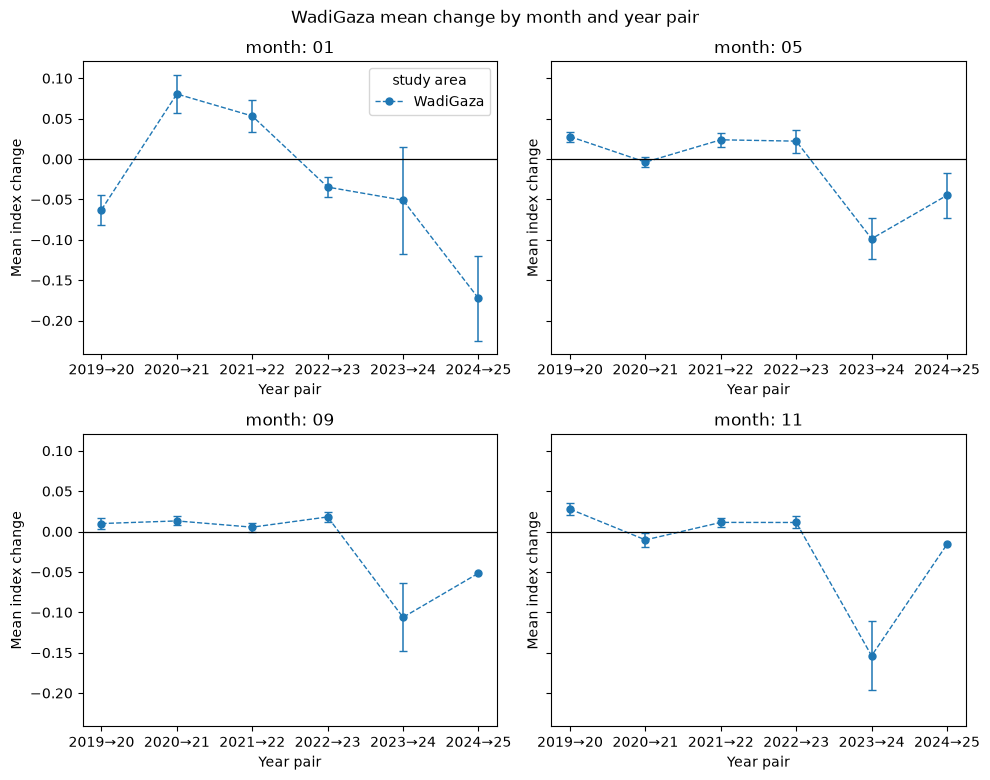

In [4]:
fig, axes = plot_change_small_multiples(
    wadi, facet_by='month', filters={'study_area': 'WadiGaza'}, ncols=2,
)
fig.suptitle('WadiGaza mean change by month and year pair', y=1.02)
save_figure(fig, PLOT_DIR / 'WadiGaza_mean_change_month_panels.png')
plt.show()

## Monthly small multiples: WadiGaza vs other areas (2023 to 2024)

Each panel compares study areas for one month. Whiskers are adjusted 95% CIs; pairs flagged for no range retain their mean marker without CI whiskers. WadiGaza is highlighted.

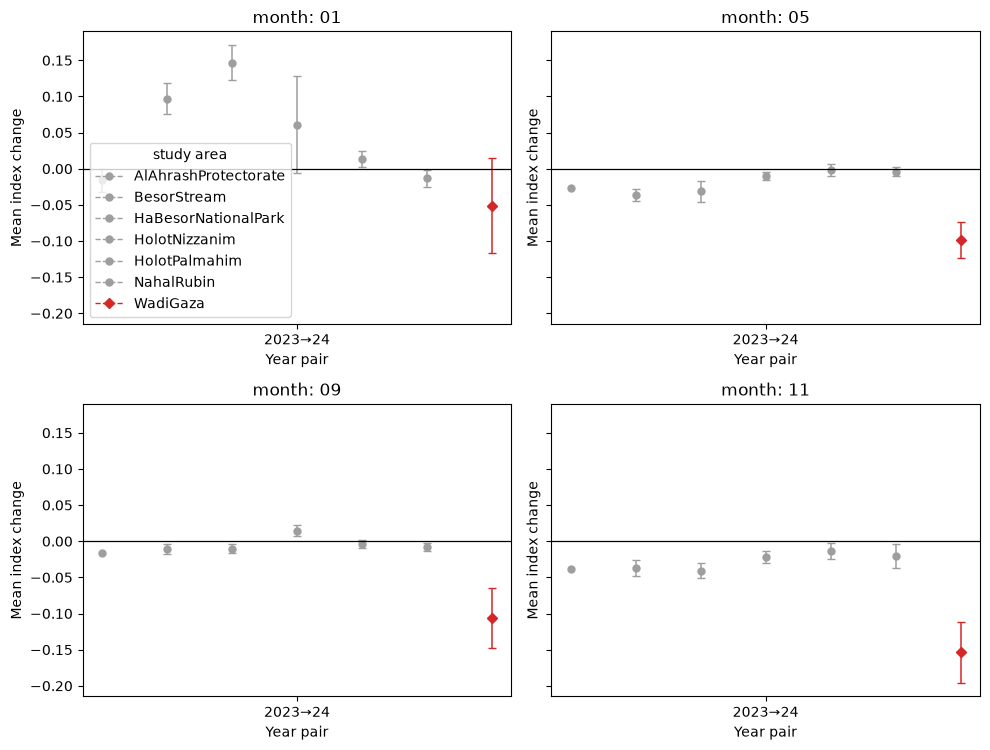

In [5]:
comparison_2023_2024 = primary.loc[
    (primary['year_start'] == 2023) & (primary['year_end'] == 2024)
].copy()
fig, axes = plot_change_small_multiples(
    comparison_2023_2024,
    facet_by='month',
    show_ci_for='all',
    ncols=2,
    highlight='WadiGaza',
)
save_figure(fig, PLOT_DIR / 'WadiGaza_vs_other_areas_2023_2024_monthly_small_multiples.png')
plt.show()

## 2023 to 2024 mean-change heatmaps by month

Each heatmap compares all study areas for one month; hollow circles mark adjusted CIs that exclude zero.

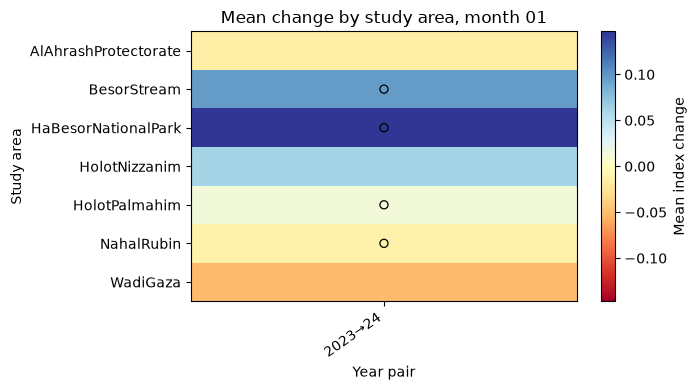

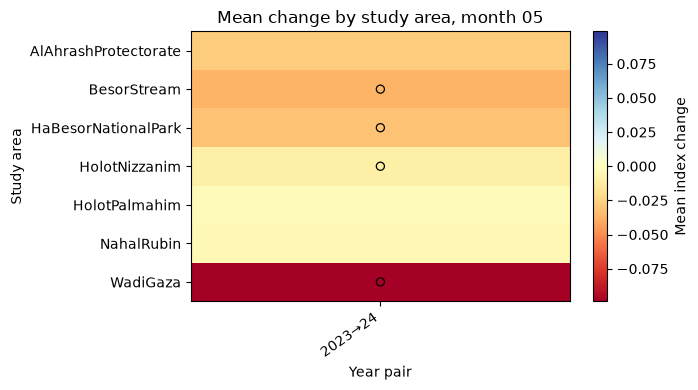

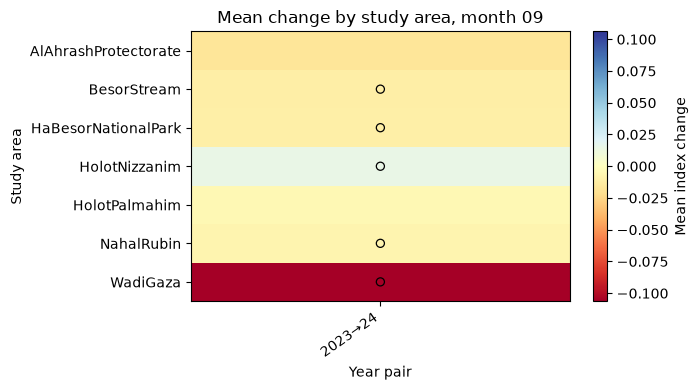

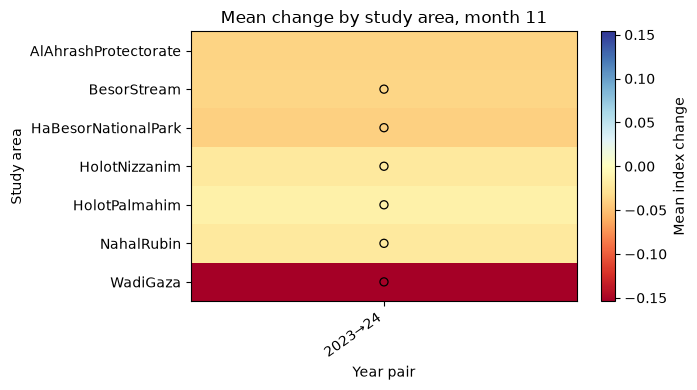

In [6]:
for month in ('01', '05', '09', '11'):
    fig, ax = plot_change_heatmap(comparison_2023_2024, month=month)
    save_figure(fig, PLOT_DIR / f'study_area_mean_change_2023_2024_month_{month}.png')
    plt.show()

## WadiGaza heatmaps and effective sample size

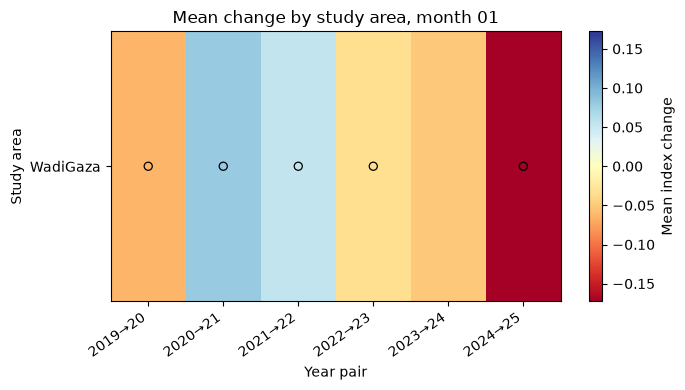

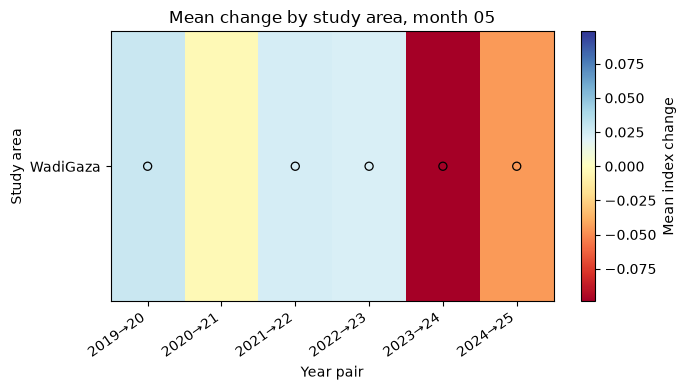

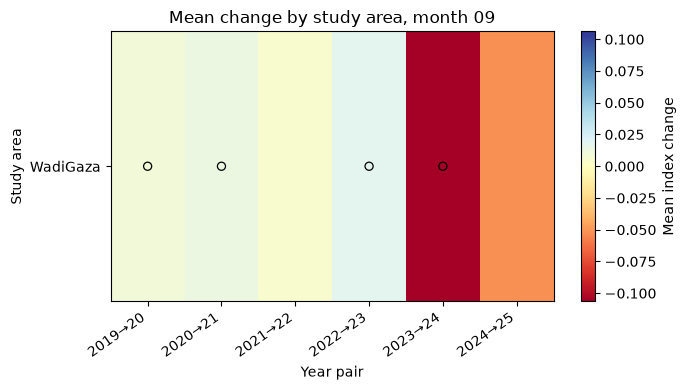

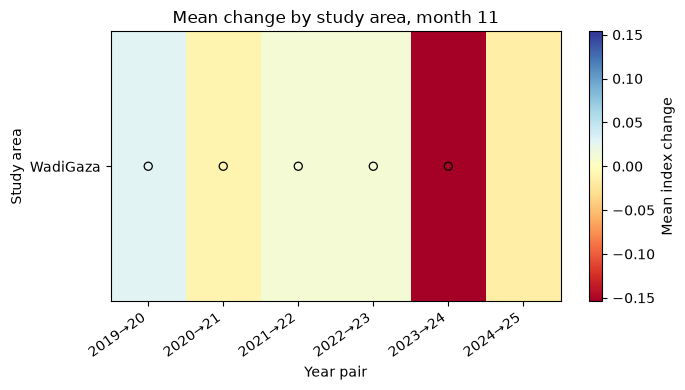

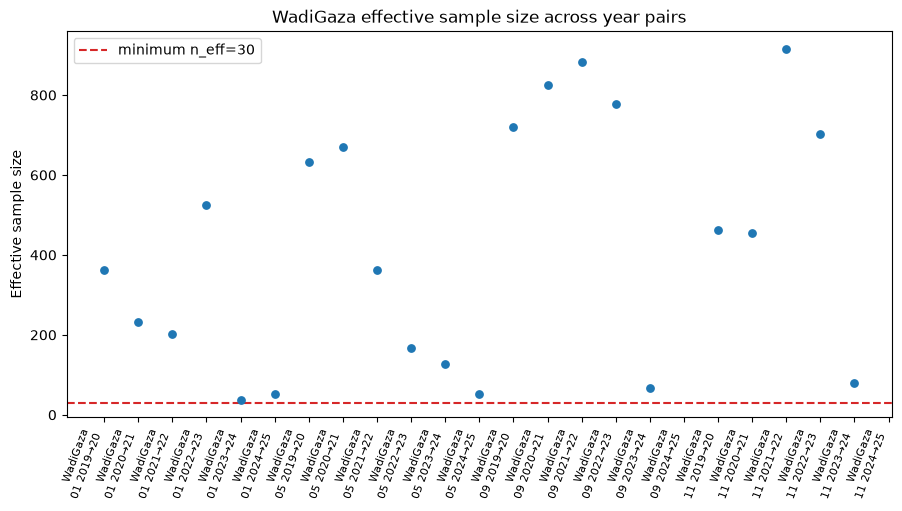

In [7]:
for month in ('01', '05', '09', '11'):
    fig, ax = plot_change_heatmap(wadi, month=month)
    save_figure(fig, PLOT_DIR / f'WadiGaza_mean_change_heatmap_{month}.png')
    plt.show()

fig, ax = plot_n_eff(wadi, min_n_eff=30)
ax.set_title('WadiGaza effective sample size across year pairs')
save_figure(fig, PLOT_DIR / 'WadiGaza_effective_sample_size.png')
plt.show()

## WadiGaza correlograms and threshold sensitivity

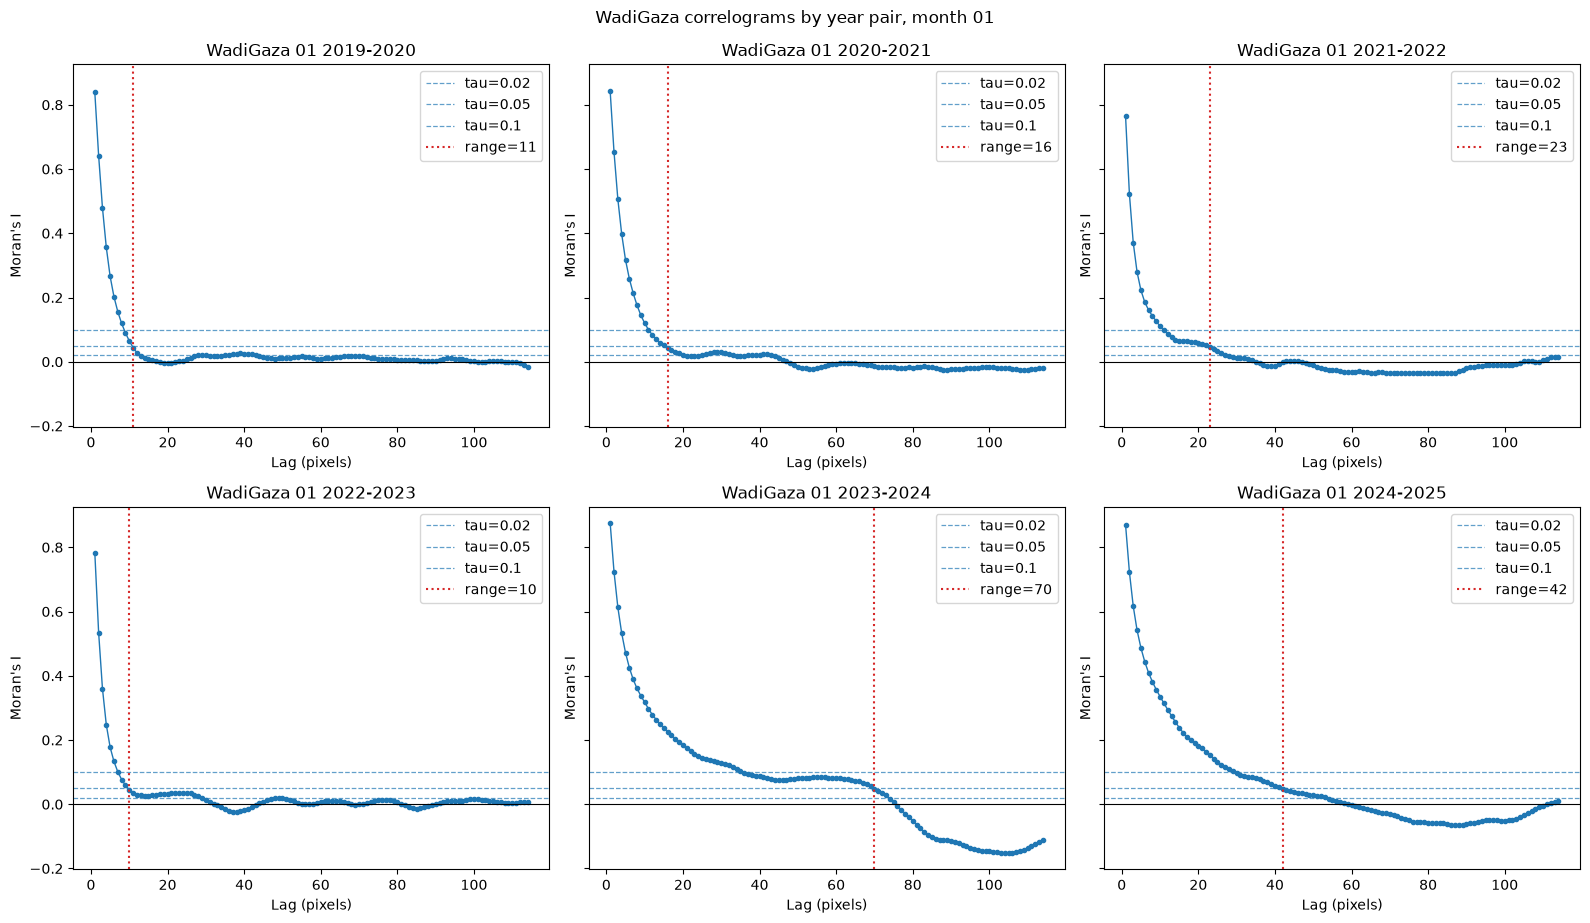

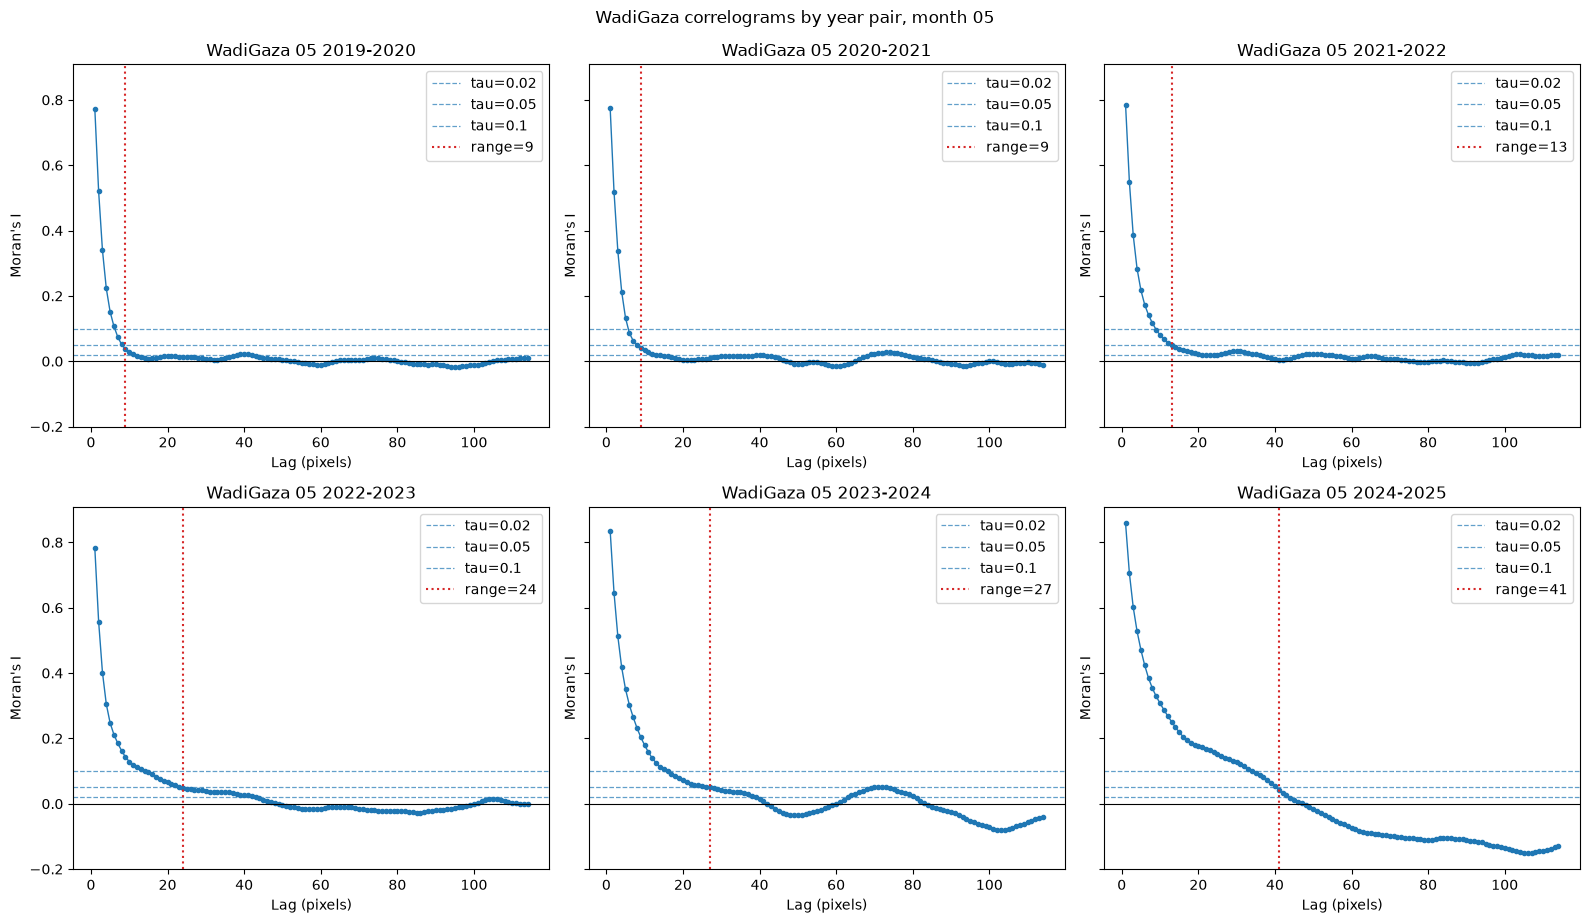

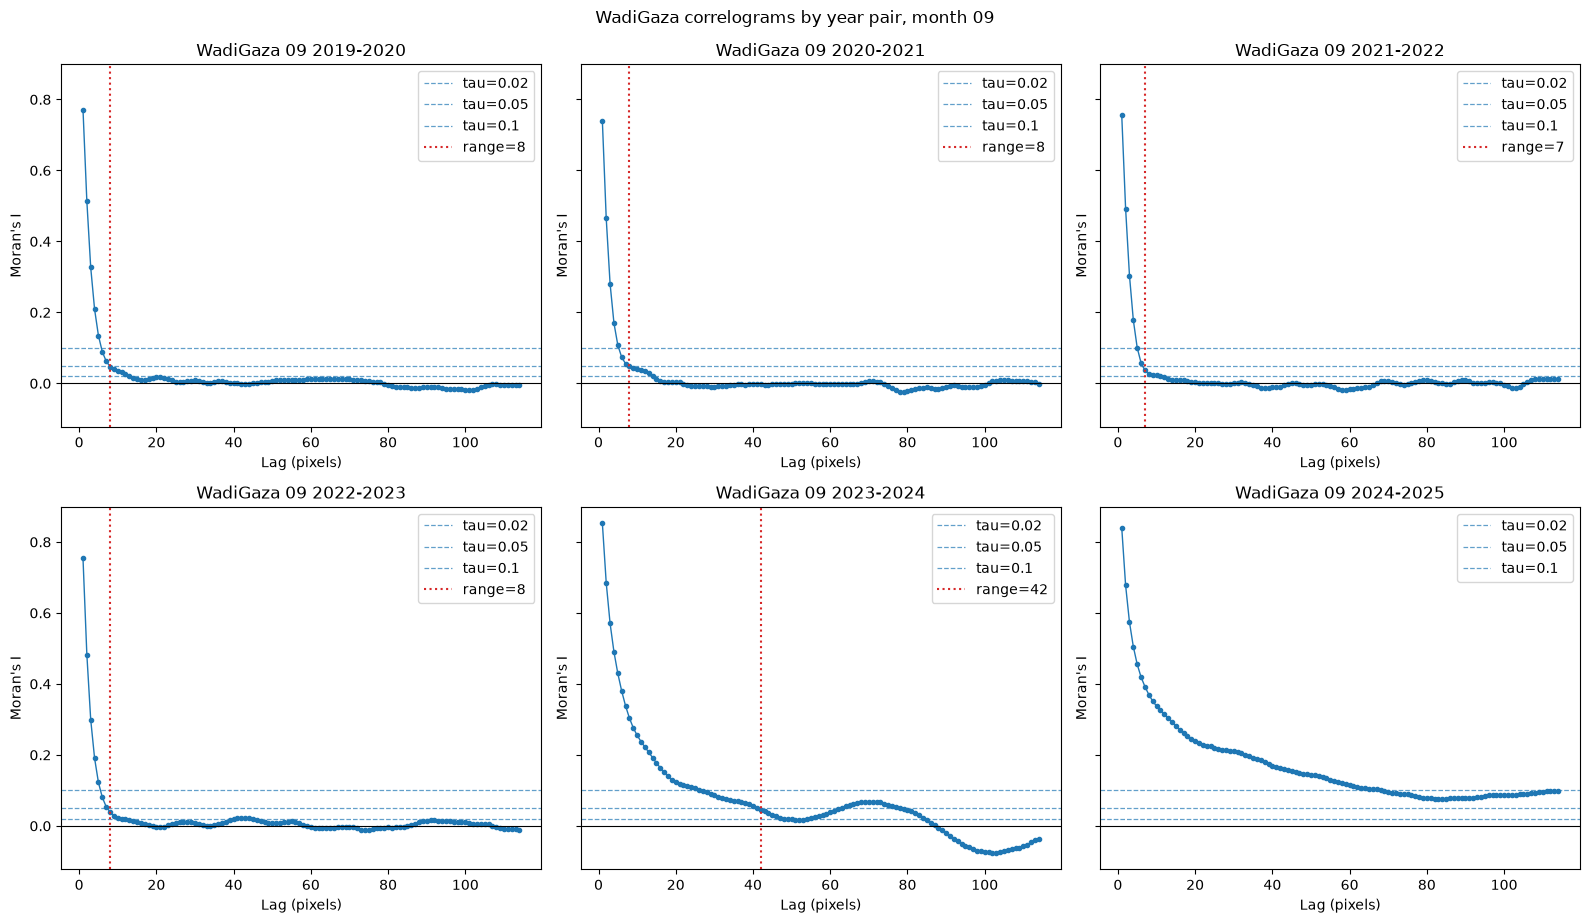

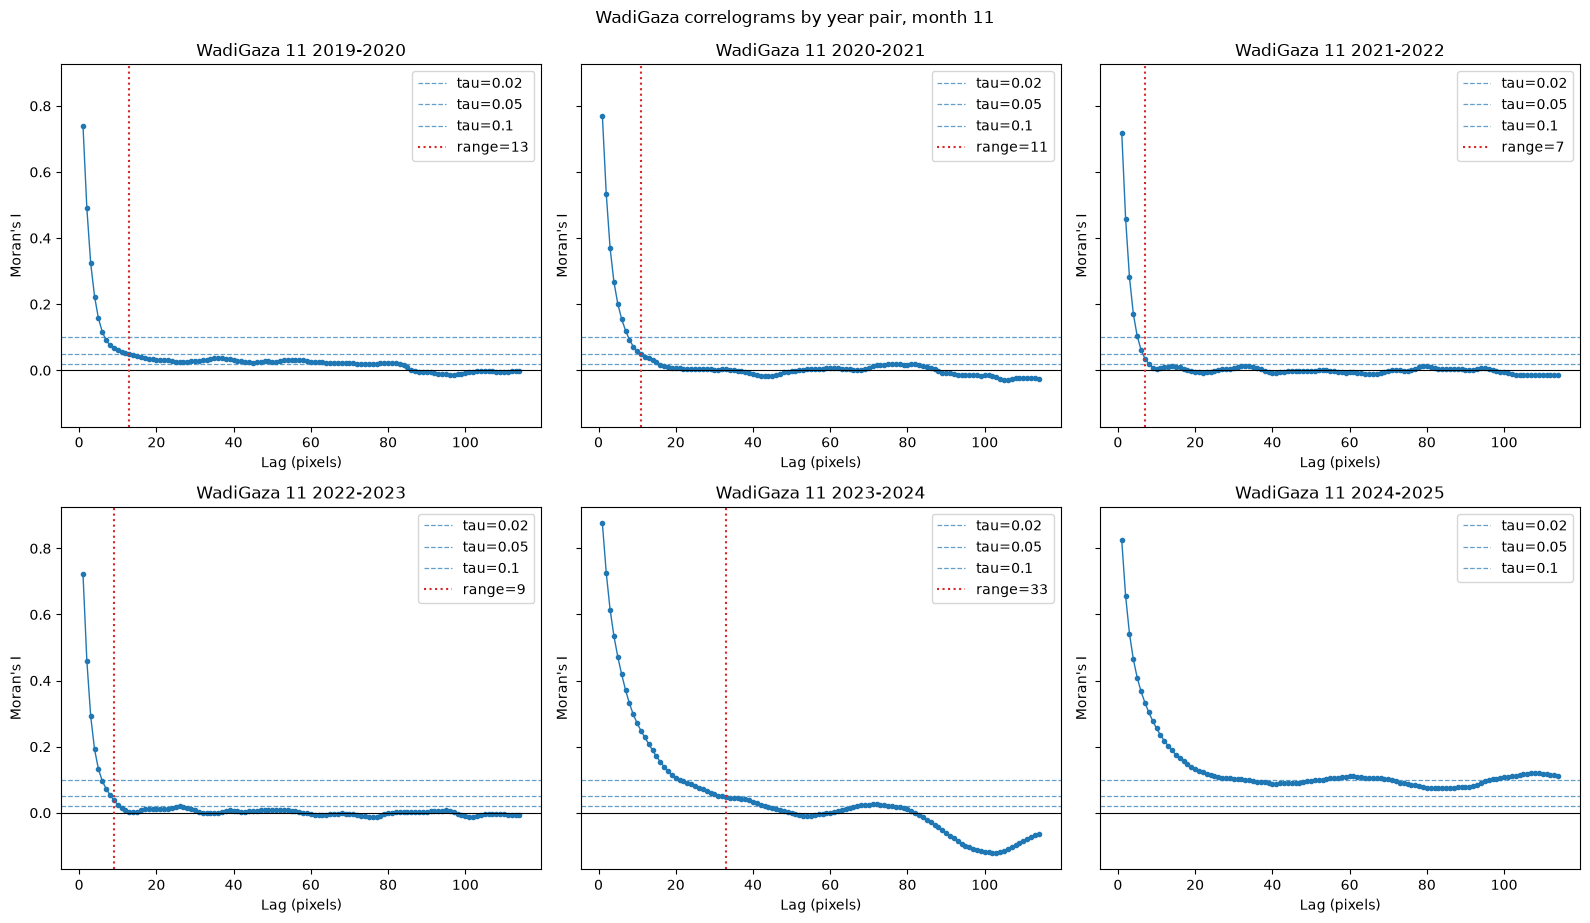

Figures saved to /home/tshihadah/code/wadi-gaza-research/outputs/change_ci/all_year_pairs_2019_2025/plots


In [8]:
for month in ['01', '05', '09', '11']:
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
    for ax, year_start in zip(axes.flat, range(2019, 2025)):
        pair = {
            'study_area': 'WadiGaza', 'month': month,
            'year_start': year_start, 'year_end': year_start + 1,
        }
        plot_correlogram(correlograms, results, pair, ax=ax)
    fig.suptitle(f'WadiGaza correlograms by year pair, month {pair["month"]}', y=1.02)
    save_figure(fig, PLOT_DIR / f'WadiGaza_{month}_correlograms_all_year_pairs.png')
    plt.show()

print(f'Figures saved to {PLOT_DIR}')